In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [2]:
# 동영상 ID
video_id = "EOCZYxmi7ho"

get url!!!
get url finished!!!!!


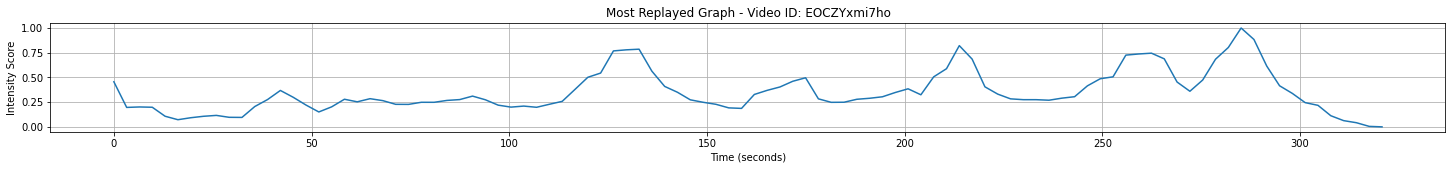

In [3]:



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


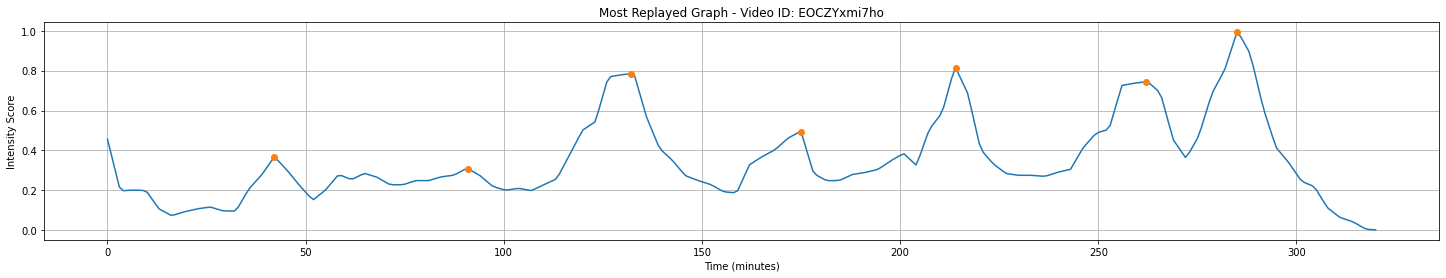

In [4]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [5]:
rewards_lst = smoothed_intensity_scores

In [44]:
class State:
    def __init__(self, time, count, rewards_lst= rewards_lst):
        self.time = time
        self.count = count
        self.reward = rewards_lst[time]
        self.frame = 0
        self.next_states = []

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [45]:
# count_durations = []  # 각 피크마다 count_duration을 계산해서 저장

# 각 피크마다 count_duration 계산
# for i, peak in enumerate(peaks):
#     if i < len(peaks) - 1:
#         count_duration = min(50, peaks[i + 1] - peak)
#     else:
#         count_duration = min(50, len(smoothed_intensity_scores) - peak)
#     count_durations.append(count_duration)

In [46]:
F = 10

In [102]:
# 초기 state 만들기
states = []
total_length = len(smoothed_intensity_scores)
cnt = 0
# for i in range(total_length):
#     states.append(State(time=i, count = 0)) 

for i in range(total_length):
    for j in range(F):
        if i + j < total_length:
            states.append(State(time=i, count = j)) 


In [103]:
for state in states:
    state.get_info()


Peak: 0, Count: 0,  Next State []
Peak: 0, Count: 1,  Next State []
Peak: 0, Count: 2,  Next State []
Peak: 0, Count: 3,  Next State []
Peak: 0, Count: 4,  Next State []
Peak: 0, Count: 5,  Next State []
Peak: 0, Count: 6,  Next State []
Peak: 0, Count: 7,  Next State []
Peak: 0, Count: 8,  Next State []
Peak: 0, Count: 9,  Next State []
Peak: 1, Count: 0,  Next State []
Peak: 1, Count: 1,  Next State []
Peak: 1, Count: 2,  Next State []
Peak: 1, Count: 3,  Next State []
Peak: 1, Count: 4,  Next State []
Peak: 1, Count: 5,  Next State []
Peak: 1, Count: 6,  Next State []
Peak: 1, Count: 7,  Next State []
Peak: 1, Count: 8,  Next State []
Peak: 1, Count: 9,  Next State []
Peak: 2, Count: 0,  Next State []
Peak: 2, Count: 1,  Next State []
Peak: 2, Count: 2,  Next State []
Peak: 2, Count: 3,  Next State []
Peak: 2, Count: 4,  Next State []
Peak: 2, Count: 5,  Next State []
Peak: 2, Count: 6,  Next State []
Peak: 2, Count: 7,  Next State []
Peak: 2, Count: 8,  Next State []
Peak: 2, Count

In [104]:
len(states)

3165

In [117]:
# 다음 상태 정의 함수
# import pdb
def fill_next_states(states, min_duration):
    for state in states:
        next_states = []
        for next_state in states:
            # 바로 다음 것
            if  (next_states.count == state.count + 1) and (next_states.time == state.time + 1):
                next_states.append(next_state)
            elif  (next_state.count >= min_duration) and (next_state.time > state.time):
                next_states.append(next_state)
        
        state.next_states = next_states
        # print(state.next_states)

fill_next_states(states, min_duration=2)


KeyboardInterrupt: 

In [ ]:
# 다음 상태 정의 함수
# import pdb
# def fill_next_states(states, min_duration):
#     for state in states:
#         # 다음 걸로 갈 수 있음
#         next_states = []
#         if state.time + 1 < total_length:
#             next_states.append(State(time = state.time + 1, count = state.count+1))

#         if (state.count >= min_duration):
#             for i in range(state.time + state.count + 2, total_length):
#                 next_states.append(State(time = i, count = 0)) # 2초 뒤에 있는것부터 가능
#         state.next_states = next_states
#         # print(state.next_states)

# fill_next_states(states, min_duration=2)

In [106]:
total_length

321

In [107]:
len(states[2].next_states)

318

In [108]:

# for state in states:
#     state.get_info()

In [115]:
# def fill_next_states(states, min_duration):
#     for state in states:
#         next_states = []
        
#         # 바로 다음 것
#         if state.time < total_length - 1:
#             next_state = State(time = state.time + 1 , count = state.count + 1)
#             if next_state not in states:
#                     states.append(next_state)

#         # 2초 이상인 경우에 대해서만 다른 피크들
#         if (state.count >= min_duration):
#             for i in range(state.time, total_length - 2):
#                 next_state = State(time = i + 2, count = 0)
#                 next_states.append(next_state)
#                 if next_state not in states:
#                     states.append(next_state)
            
#         state.next_states = next_states
#         # print(state.next_states)
# fill_next_states(states, min_duration=2)


KeyboardInterrupt: 

In [110]:
# for state in states:
#     state.get_info()

In [111]:
# time, 현재 담긴 시간
# count, 지속 시간
#frame 최종 summarize 시간

In [112]:
def find_highlights(states, F):
    dp = np.zeros((len(states), ))
    path = [[None for _ in range(F+1)] for _ in range(len(states))]
    
    print("start DP!!!")
    for f in range(1, F+1):
        print(f)
        for i, state in enumerate(states):
            max_prev_reward = -float('inf')
            best_prev_state = None
            for prev_state in state.next_states:
                prev_idx = states.index(prev_state)
                if dp[prev_idx][f-1] + state.reward > max_prev_reward:
                    max_prev_reward = dp[prev_idx][f-1] + state.reward
                    best_prev_state = prev_idx
            if best_prev_state is not None:
                dp[i][f] = max_prev_reward
                path[i][f] = best_prev_state
    print("finished DP!!!")
    
    highlights = []
    state_idx = np.argmax(dp[:, -1])
    f = F
    while f > 0 and state_idx is not None:
        highlights.append(states[state_idx].time)
        state_idx = path[state_idx][f]        
        f -= 1

    return highlights

# 예시 데이터
peaks = peaks
smoothed_intensity_scores = smoothed_intensity_scores


highlights = find_highlights(states, F)


start DP!!!
1


ValueError: <__main__.State object at 0x7fedda1cc5b0> is not in list

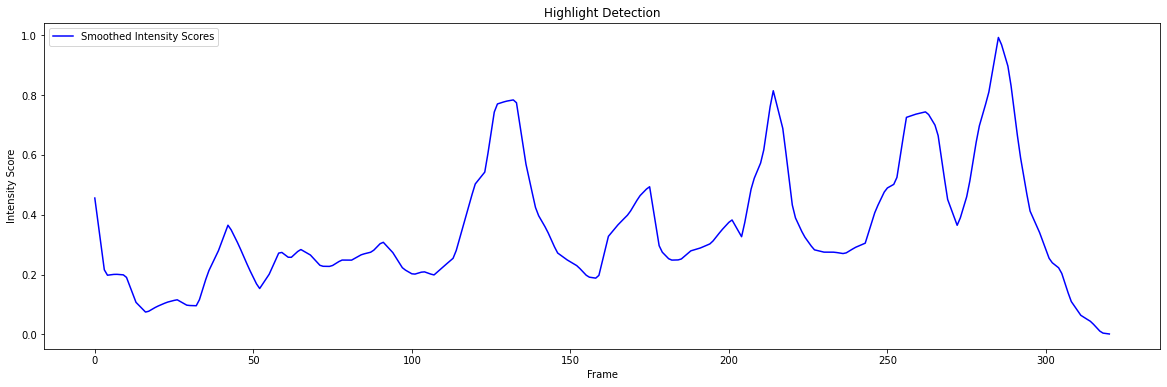

In [114]:
# 그래프 그리기
plt.figure(figsize=(20, 6))
plt.plot(smoothed_intensity_scores, 'b-', label='Smoothed Intensity Scores')
for point in highlights:
    plt.scatter(point, smoothed_intensity_scores[point], color='red', s=50)  # s는 점의 크기


plt.xlabel('Frame')
plt.ylabel('Intensity Score')
plt.title('Highlight Detection')
plt.legend()
plt.show()